# Project 1: Teammate 1 walkthrough
**Dataset:** TweetEval emoji · **Our part:** data, metric, tokenizer, features (+ the leak we discovered)

Run this notebook **one cell at a time, from top to bottom** (click a cell, press `Shift + Enter`).
Every step has three parts:
1. 📖 **What & why**: plain-English explanation
2. ▶️ **Code**: short; the heavy lifting lives in `project/lib.py`
3. 👀 **What to look at**: how to read the output

| Step | "Get to work!" item | What we do |
|---|---|---|
| 0 | – | Setup |
| 1 | #1 Choose a dataset, understand it | Load TweetEval emoji, look at tweets and label counts |
| 2 | #5 Evaluate (which metric?) | Why accuracy misleads → macro-F1 |
| 3 | #1 (understand the data) | 🔍 The hidden leak we found |
| 4 | #2 Tokenizer | Train BPE, choose the vocabulary size |
| 5 | #3 Features | Indicator, bag-of-words, bag-of-words + bigrams |
| 6 | Extra | How much the leak inflates results |
| 7 | – | Summary + what Teammate 2 does next |

## Step 0: Setup
📖 We tell Python where our code lives (the repository root) and import our helper module `project.lib`.
`%matplotlib inline` makes plots appear inside the notebook.

In [1]:
import sys, json
from pathlib import Path
from collections import Counter

ROOT = Path.cwd().parent if Path.cwd().name == "project" else Path.cwd()   # works if opened from root or project/
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

from project import lib
RESULTS = ROOT / "results" / "project"
print("Repository root:", ROOT)
print("Saved results  :", RESULTS, "exists =", RESULTS.exists())

Repository root: /Users/pravallikareddy/Downloads/nlp1-student-main
Saved results  : /Users/pravallikareddy/Downloads/nlp1-student-main/results/project exists = True


## Step 1: The dataset (Get to work #1)
📖 **TweetEval emoji**: researchers took tweets that contained exactly one of 20 popular emojis,
**deleted the emoji from the text**, and kept it as the label.
Our task: *read the words and guess which emoji was there.*

`load_tweeteval_emoji()` downloads it (only the first time) and returns three splits as lists of `(text, label)` pairs.

In [2]:
train, val, test, emojis = lib.load_tweeteval_emoji()        # raw data, exactly as published

print(f"train: {len(train):,} tweets   validation: {len(val):,}   test: {len(test):,}")
print("the 20 classes:", " ".join(emojis))

train: 45,000 tweets   validation: 5,000   test: 50,000
the 20 classes: ❤ 😍 😂 💕 🔥 😊 😎 ✨ 💙 😘 📷 🇺🇸 ☀ 💜 😉 💯 😁 🎄 📸 😜


📖 **How we use the three splits**
- **train (45k)** → cross-validation: train on 4/5, evaluate on 1/5, rotate.
- **validation (5k)** → only for *choices* (e.g. tokenizer size).
- **test (50k)** → touched only at the very end, so the final numbers are honest.

Let's look at a few real tweets:

In [3]:
for text, label in train[:8]:
    print(f"{emojis[label]}  |  {text}")

☀  |  Sunday afternoon walking through Venice in the sun with @user ️ ️ ️ @ Abbot Kinney, Venice
😜  |  Time for some BBQ and whiskey libations. Chomp, belch, chomp! (@ Lucille's Smokehouse Bar-B-Que)
❤  |  Love love love all these people ️ ️ ️ #friends #bff #celebrate #blessed #sundayfunday @ San…
❤  |  ️ ️ ️ ️ @ Toys"R"Us
😂  |  Man these are the funniest kids ever!! That face! #HappyBirthdayBubb @ FLIPnOUT Xtreme
🇺🇸  |  #sandiego @ San Diego, California
❤  |  My little ️ ️ ️ ️ ️ #ObsessedWithMyDog @ Cafe Solstice Capitol Hill
😜  |  More #tinyepic things #tinyepicwestern, this one is crazy @user I may be one of your…


👀 Notice: short texts, hashtags (`#friends`), mentions (`@user`), and **location tags** like `@ Venice` (Instagram-style).

Next: **how many tweets per emoji?**

In [4]:
counts = Counter(label for _, label in train)
table = pd.DataFrame({
    "emoji": [emojis[k] for k in range(20)],
    "tweets": [counts[k] for k in range(20)],
    "share %": [round(100 * counts[k] / len(train), 1) for k in range(20)],
}).sort_values("tweets", ascending=False).reset_index(drop=True)
table

,emoji,tweets,share %
0,❤,9204,20.5
1,😍,4901,10.9
2,😂,4713,10.5
3,✨,2345,5.2
4,🔥,2146,4.8
5,😊,2132,4.7
6,😎,2078,4.6
7,💕,2043,4.5
8,📷,1982,4.4
9,📸,1510,3.4


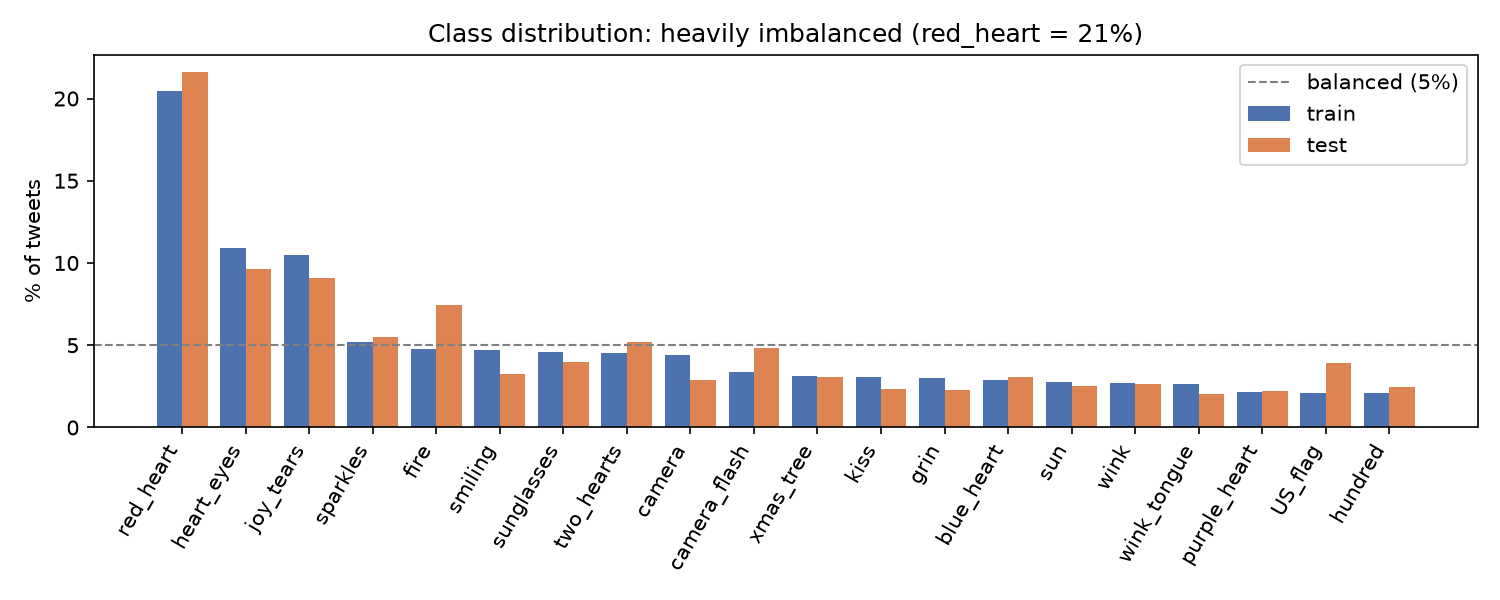

In [5]:
display(Image(RESULTS / "figures" / "class_distribution.png", width=800))

👀 **Heavily imbalanced.** ❤ alone is about 21% of all tweets, while 💯 and 🇺🇸 are about 2%.
If the classes were balanced, each would be 5% (dashed line). Keep this in mind for Step 2.

In [6]:
lengths = [len(text.split()) for text, _ in train]
print(f"words per tweet: median {np.median(lengths):.0f}, mean {np.mean(lengths):.1f}, max {max(lengths)}")

words per tweet: median 12, mean 11.8, max 39


## Step 2: Which metric? (Get to work #5)
📖 **Accuracy** = % of tweets where we guessed the right emoji.
**Macro-F1** = compute an F1 score *for each emoji separately*, then take the plain average, so every emoji counts equally, rare or common.

Test with the dumbest possible "model": **always answer ❤**.

In [7]:
from sklearn.metrics import accuracy_score, f1_score

y_test = np.array([label for _, label in test])
always_heart = np.zeros_like(y_test)          # label 0 = ❤

print(f"'always ❤'  accuracy = {100*accuracy_score(y_test, always_heart):.1f}%")
print(f"'always ❤'  macro-F1 = {100*f1_score(y_test, always_heart, average='macro', zero_division=0):.1f}%")

'always ❤'  accuracy = 21.6%
'always ❤'  macro-F1 = 1.8%


👀 **21.6% accuracy** for a model that learned *nothing*, but only **1.8% macro-F1**.
Accuracy rewards ignoring 19 of the 20 emojis. Macro-F1 doesn't.
➡️ **Decision: macro-F1 is our main metric** (accuracy reported alongside). It's also TweetEval's official metric for this task.

## Step 3: 🔍 The hidden leak we discovered
📖 Some emojis are stored as **two** Unicode characters: the emoji itself + an invisible "variation selector" `U+FE0F`
that says "draw me in colour" (e.g. ❤️ = `❤` + `U+FE0F`).
When the dataset creators deleted the emoji, they **left the invisible part behind**.

You can't see it when you `print`, but `ascii()` writes every non-English character as its code number, so it shows up:

In [8]:
example = train[2][0]
print("print():", example)
print("ascii():", ascii(example))
print("contains U+FE0F?", lib.LEAK_CHAR in example, "   label:", emojis[train[2][1]])

print(): Love love love all these people ️ ️ ️ #friends #bff #celebrate #blessed #sundayfunday @ San…
ascii(): 'Love love love all these people \ufe0f \ufe0f \ufe0f #friends #bff #celebrate #blessed #sundayfunday @ San\u2026'
contains U+FE0F? True    label: ❤


👀 In the `ascii()` line, each `\ufe0f` is a leftover invisible character (`\u2026` at the end is just "…").
In the `print()` line you only see some odd extra spaces where they are. Now: **which labels have tweets containing it?**

In [9]:
rows = []
for k in range(20):
    tweets_k = [t for t, l in train if l == k]
    rows.append({"emoji": emojis[k], "% tweets with U+FE0F": round(100 * np.mean([lib.LEAK_CHAR in t for t in tweets_k]), 1)})
pd.DataFrame(rows).sort_values("% tweets with U+FE0F", ascending=False).head(5)

,emoji,% tweets with U+FE0F
12,☀,96.4
0,❤,83.7
1,😍,0.1
16,😁,0.1
15,💯,0.1


👀 Only **❤ (84%)** and **☀ (96%)**. Exactly the two emojis that need `U+FE0F`.
So a model can "cheat": *see the invisible character → answer ❤*. That's a **label leak**.

Is it the same in all three splits?

In [10]:
for name, split in [("train", train), ("validation", val), ("test", test)]:
    share = np.mean([lib.LEAK_CHAR in t for t, _ in split])
    print(f"{name:10s}: {100*share:5.1f}% of tweets contain U+FE0F")

train     :  19.8% of tweets contain U+FE0F
validation:   1.6% of tweets contain U+FE0F
test      :  21.0% of tweets contain U+FE0F


👀 **The validation split was cleaned, but train and test were not.** The splits are inconsistent.

➡️ **Decision:** remove `U+FE0F` from **every** split before any experiment (`lib.clean_leak`).
The function replaces it with a space and squeezes extra spaces:

In [11]:
print(repr(lib.clean_leak(example)))

'Love love love all these people #friends #bff #celebrate #blessed #sundayfunday @ San…'


In [12]:
# From here on we use the CLEAN data
train, val, test, emojis = lib.load_tweeteval_emoji(clean=True)
train_texts = [t for t, _ in train]
print("leak left in train:", sum(lib.LEAK_CHAR in t for t in train_texts))

leak left in train: 0


## Step 4: The tokenizer (Get to work #2)
📖 Before turning tweets into numbers, we cut them into pieces (**tokens**). We use **BPE**, exactly like the tutorial:
start from single characters and repeatedly glue the most frequent neighbouring pair into a new token, until the vocabulary has *V* tokens.

**Questions from the project sheet, and our answers:**
- *Train a new one?* Yes. Tweets differ a lot from news (hashtags, slang), so the tutorial's AG-News tokenizer is a poor fit.
- *On what data?* The 45k **training** tweets only (never test). It uses only the text, not the labels.
- *Is the dataset too small?* 45k tweets ≈ 530k words, enough for BPE at the vocab sizes we need (results below).
- *Which hyperparameters?* `min_frequency=2` (as in the tutorial) and the **vocabulary size chosen by experiment**.

Let's train one with V = 16,000 (takes a few seconds) and tokenize a tweet:

In [13]:
tokenizer = lib.train_bpe(train_texts, vocab_size=16000)

tweet = "Best day ever with my girls #blessed @ San Diego"
print(tokenizer.encode(tweet).tokens)


['▁Best', '▁day', '▁ever', '▁with', '▁my', '▁girls', '▁#blessed', '▁@', '▁San', '▁Diego']


👀 `▁` marks "a space was here". Common words and even hashtags become single tokens.
Now a **small vocabulary** (500) on the same tweet:

In [14]:
small = lib.train_bpe(train_texts, vocab_size=500)
print(small.encode(tweet).tokens)
print("actual vocab size:", small.get_vocab_size())



['▁', 'B', 'e', 's', 't', '▁', 'd', 'a', 'y', '▁', 'e', 'v', 'e', 'r', '▁', 'w', 'i', 't', 'h', '▁', 'm', 'y', '▁', 'g', 'i', 'r', 'l', 's', '▁', '#', 'b', 'l', 'e', 's', 's', 'e', 'd', '▁', '@', '▁', 'S', 'a', 'n', '▁', 'D', 'i', 'e', 'g', 'o']
actual vocab size: 557


👀 Almost single characters! Tweets contain about **557 different characters** (accents, symbols, other scripts),
so a budget of 500 is used up by the alphabet and **no merges happen**.

### Choosing V
📖 We tried 7 sizes. For each: train BPE → bag-of-words → logistic regression on train → **macro-F1 on the validation split**
(validation, not test and not the CV folds, so this choice doesn't leak into later results).
Script: `project/tokenizer_vocab.py` (about 3 minutes). Here we load its saved results:

In [15]:
vocab_results = pd.DataFrame(json.loads((RESULTS / "tokenizer_vocab.json").read_text()))
vocab_results["macro_f1 %"] = (100 * vocab_results["macro_f1"]).round(1)
vocab_results[["vocab_size", "tokens_per_tweet", "features_seen_in_<5_tweets", "macro_f1 %"]]

,vocab_size,tokens_per_tweet,features_seen_in_<5_tweets,macro_f1 %
0,500,71.54,424,8.9
1,1000,32.52,425,17.5
2,2000,25.39,430,19.7
3,4000,21.48,454,20.3
4,8000,18.79,575,21.4
5,16000,16.79,1172,22.2
6,32000,15.22,13234,22.6


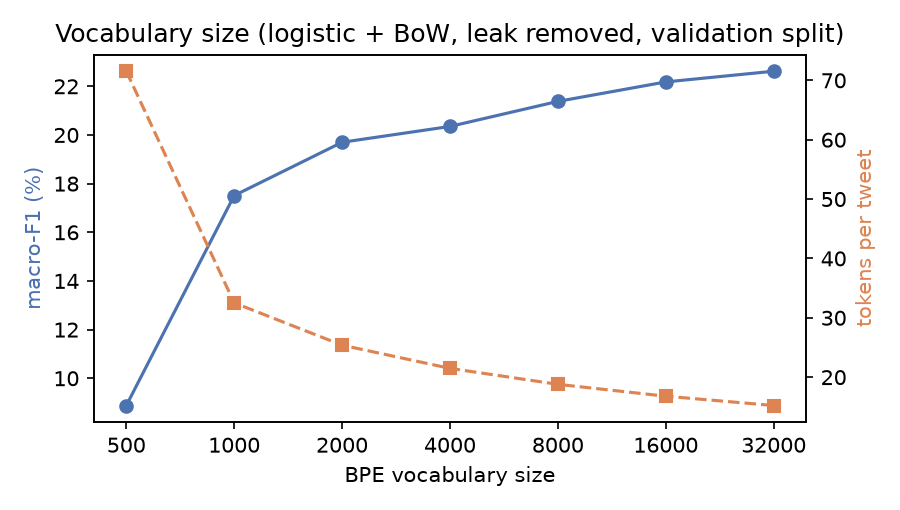

In [16]:
display(Image(RESULTS / "figures" / "vocab_size.png", width=600))

👀 Bigger vocabulary → better, but with **diminishing returns** (16k → 32k adds only 0.4 points),
and at 32k about 13,000 tokens appear in fewer than 5 tweets: features with almost no data to learn from.
➡️ **Decision: V = 16,000.**

## Step 5: Features (Get to work #3)
📖 A model needs **numbers**, so each tweet becomes a vector with one position per feature. We compare three ways:

| Encoder | Value at a token's position | Dimensions | From |
|---|---|---|---|
| **Token indicator** | 1 if the token occurs, else 0 | 16,000 | tutorial |
| **Bag-of-words** | how many times it occurs | 16,000 | tutorial |
| **BoW + bigrams** | counts, plus counts of *pairs of neighbouring tokens* | 36,000 | **our choice** |

Why bigrams? Bag-of-words forgets word order. Bigrams keep a little of it: "not good" ≠ "good", `San+Diego` becomes one feature.

In [17]:
indicator = lib.TokenIndicator(tokenizer)
bow       = lib.BagOfWords(tokenizer)
bigrams   = lib.BagOfNgrams(tokenizer, train_texts)     # learns the 20k most frequent token pairs from training tweets

for enc in [indicator, bow, bigrams]:
    print(f"{enc.name:12s} -> {len(enc):,} dimensions")

indicator    -> 16,000 dimensions
bow          -> 16,000 dimensions
bow+bigrams  -> 36,000 dimensions


Let's see the **non-zero** entries for one tweet in each space (all other entries are 0, which is why we store vectors *sparsely*):

In [18]:
id2tok = {i: t for t, i in tokenizer.get_vocab().items()}
pair_of = {j: pair for pair, j in bigrams.bigram_index.items()}

def show(encoder, text):
    row = encoder.transform([text])[0]                      # sparse vector
    feats = []
    for j, value in zip(row.indices, row.data):
        name = id2tok[j] if j < bigrams.V else id2tok[pair_of[j][0]] + "+" + id2tok[pair_of[j][1]]
        feats.append(f"{name}={value:g}")
    print(f"{encoder.name:12s} ({row.nnz} non-zeros): " + ", ".join(feats))

text = "so so happy with my best friend"
for enc in [indicator, bow, bigrams]:
    show(enc, text)

indicator    (6 non-zeros): ▁with=1, ▁happy=1, ▁so=1, ▁best=1, ▁friend=1, ▁my=1
bow          (6 non-zeros): ▁so=2, ▁happy=1, ▁with=1, ▁my=1, ▁best=1, ▁friend=1
bow+bigrams  (12 non-zeros): ▁so=2, ▁happy=1, ▁with=1, ▁my=1, ▁best=1, ▁friend=1, ▁so+▁so=1, ▁so+▁happy=1, ▁happy+▁with=1, ▁with+▁my=1, ▁my+▁best=1, ▁best+▁friend=1


👀
- **indicator**: `▁so=1` (present, no matter how often)
- **bow**: `▁so=2` (counted twice)
- **bow+bigrams**: also pair features such as `▁best+▁friend`

## Step 6: Extra, how much does the leak inflate results?
📖 Same system (bag-of-words + bigrams, logistic regression), trained on all 45k training tweets, evaluated on the 50k test tweets, 3 seeds.
Four combinations: trained **with/without** leak × tested **with/without** leak.
Script: `project/leakage.py` (about 2 minutes). Saved results:

In [19]:
summary = json.loads((RESULTS / "leakage" / "bow+bigrams__logistic.json").read_text())["summary"]
pd.DataFrame(summary).T.mul(100).round(1)

,macro_f1,accuracy,f1_red_heart,f1_sun,f1_other_18
trained on raw | raw test,25.6,39.1,82.4,42.1,21.6
trained on raw | clean test,18.7,22.1,12.9,4.8,19.8
trained on clean | raw test,19.4,26.7,39.5,25.2,18.0
trained on clean | clean test,19.5,26.5,39.0,27.7,18.0


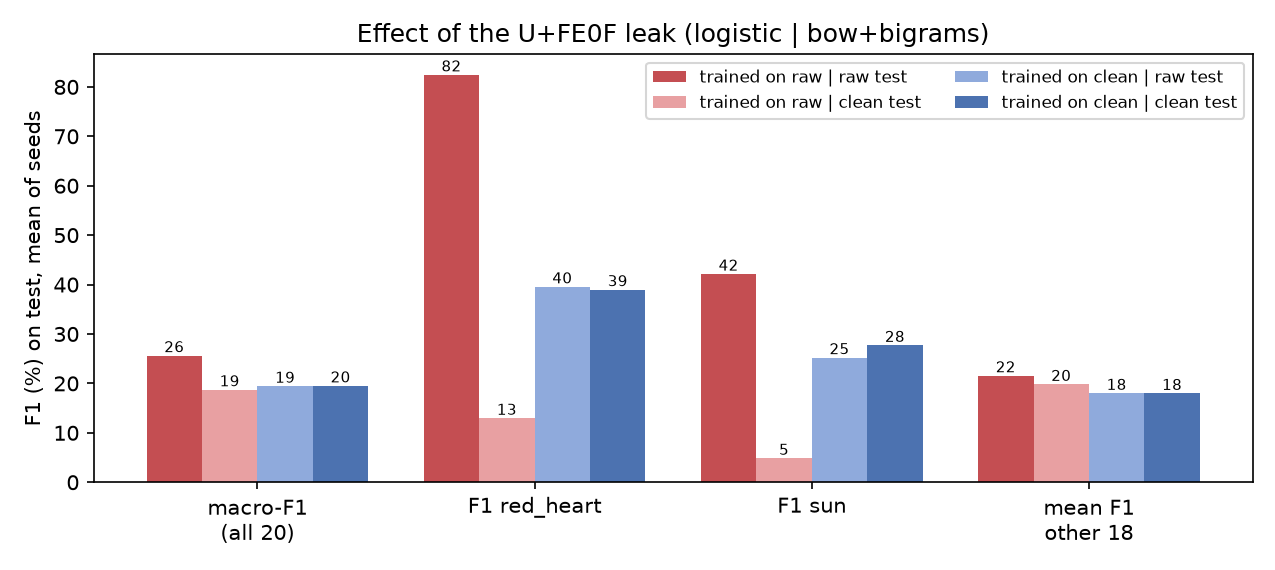

In [20]:
display(Image(RESULTS / "figures" / "leakage__bow+bigrams__logistic.png", width=800))

👀 How to read it:
1. **With the leak** the system looks much better: macro-F1 **25.6**, ❤ F1 **82**.
2. **Honest** (no leak anywhere): macro-F1 **19.5**, ❤ F1 **39**. The leak was worth about **6 points** that have nothing to do with language.
3. **Trained with leak, tested without**: ❤ F1 collapses to **13**. The model had learned *"no invisible character → not ❤"*. That's **shortcut learning**.

➡️ This is why every reported experiment uses the cleaned data.

## Step 7: Summary
| Get to work item | What we did | Decision |
|---|---|---|
| #1 Dataset | TweetEval emoji: 45k / 5k / 50k, 20 classes, very imbalanced | – |
| #1 Understand it | found the `U+FE0F` label leak, inconsistent across splits | remove it everywhere |
| #2 Tokenizer | BPE trained on training tweets; 7 vocab sizes compared on validation | **V = 16,000** |
| #3 Features | indicator, bag-of-words, **BoW + bigrams** (ours) | all three go into the comparison |
| #5 Metric | "always ❤" = 21.6% accuracy but 1.8% macro-F1 | **macro-F1** |

**Next (Teammate 2):** the three architectures (#4), cross-validation of all 9 combinations + Bayesian ROPE analysis (#5), choosing the best (#6):
```
.venv/bin/python -m project.run_experiments
```